In [1]:
import numpy as np
import cv2
IMG=r"C:\Users\SHUS\Desktop\cup_shots\cup.jpg"
BG=r"C:\Users\SHUS\Desktop\cup_shots\bg.jpg"
ROI=(700, 800, 400, 700)
img=cv2.imread(IMG)
bg=cv2.imread(BG)
x,y,w,h=ROI
a_img=img[y:y+h,x:x+w]
a_bg=bg[y:y+h,x:x+w]
g1=cv2.cvtColor(a_img,cv2.COLOR_BGR2GRAY)
g2=cv2.cvtColor(a_bg,cv2.COLOR_BGR2GRAY)
g1=cv2.GaussianBlur(g1,(7,7),0)
g2=cv2.GaussianBlur(g2,(7,7),0)

In [2]:
diff=cv2.absdiff(g1,g2)

In [3]:
t,mask=cv2.threshold(diff,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

In [4]:
k=np.ones((3,3),np.uint8)
mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,k)
mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,k)

In [5]:
n,labels,stats,centroid=cv2.connectedComponentsWithStats(mask,connectivity=8)
areas=stats[1:,4]
best=1+int(np.argmax(areas))
mask2=(labels==best).astype(np.uint8)*255

In [6]:
x,y,w,h,area=stats[best]
H,W=mask.shape
touches=(x<=1)or(y<=1)or(x+w>=W-1)or(y+h>=H-1)
if touches:
    print("Useless")
else:
    print("Usable")

Usable


In [7]:
if not touches:
    lefts=[]
    rights=[]
    rows=[]
    for yy in range(mask2.shape[0]):
        xs=np.nonzero(mask2[yy])[0]
        if xs.size==0:
            continue
        left,right=int(xs.min()),int(xs.max())
        rows.append(yy)
        lefts.append(left)
        rights.append(right)
    if len(rows)>0:
        y_min=rows[0]
        y_max=rows[-1]
        print(f"accross:{y_max-y_min+1}")
        width=[r-l+1 for l,r in zip(lefts,rights)]
        max_w=max(width)
        print(f"width:{max_w}")
        if 300 in rows:
            idx=rows.index(300)
            print(f"left:{lefts[idx]},right:{rights[idx]}")

accross:577
width:162
left:88,right:233


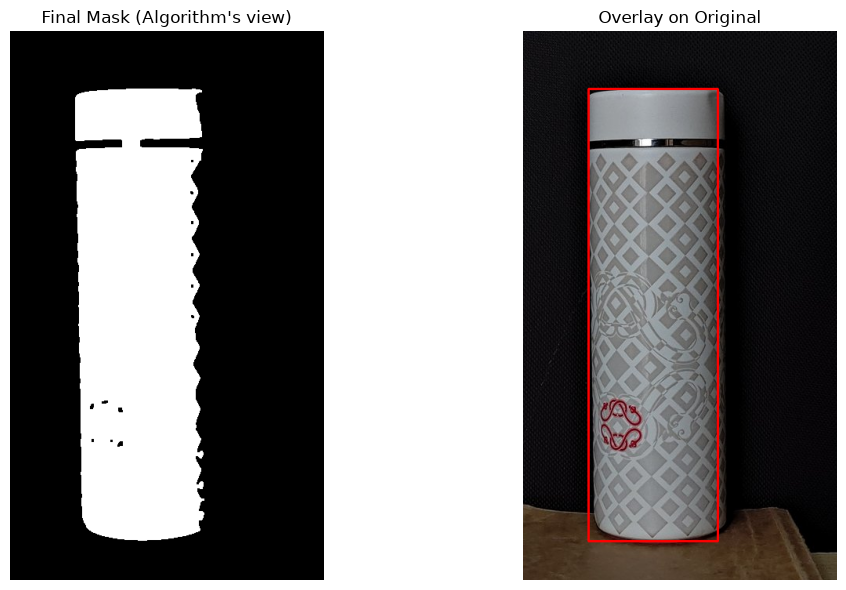

In [8]:
import matplotlib.pyplot as plt
overlay_img = a_img.copy()
if not touches and n > 1:
    cv2.rectangle(overlay_img, (x, y), (x+w, y+h), (0, 0, 255), 2)
    if 'left_edge' in locals() and 'right_edge' in locals():
        cv2.circle(overlay_img, (left_edge, 300), 4, (255, 0, 0), -1)
        cv2.circle(overlay_img, (right_edge, 300), 4, (255, 0, 0), -1)
img_rgb = cv2.cvtColor(overlay_img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Final Mask (Algorithm's view)")
plt.imshow(mask2 if not touches else mask, cmap='gray') 
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title("Overlay on Original")
plt.imshow(img_rgb)
plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
# 输入：T1 的 rows, lefts, rights（577 个）
# 输入：你量的 213.0
rows=np.array(rows)
scale = 213.0 / (rows.max() - rows.min() + 1)
z = (rows.max() - rows) * scale
r = (np.array(rights) - np.array(lefts) + 1) / 2 * scale

max_dia  = 2 * np.percentile(r, 95)
base_dia = 2 * np.median(r[-30:])
print(f"{max_dia} {base_dia} {scale}")

59.06412478336222 52.97313691507799 0.36915077989601386


Text(0, 0.5, 'width (px)')

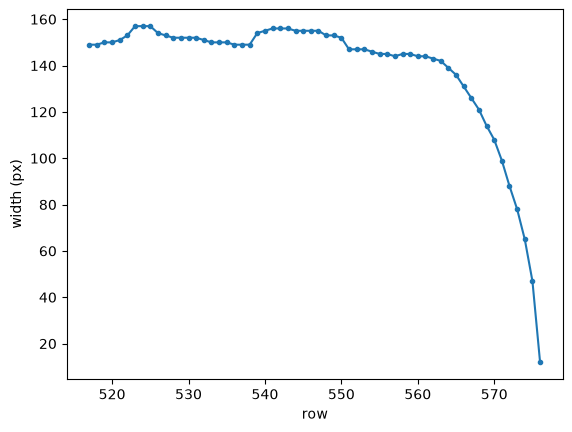

In [10]:
# 用你 T1 的数据，画底部 60 行的宽度
w = np.array(rights) - np.array(lefts) + 1
plt.plot(range(len(w)-60, len(w)), w[-60:], '.-')
plt.xlabel("row"); plt.ylabel("width (px)")

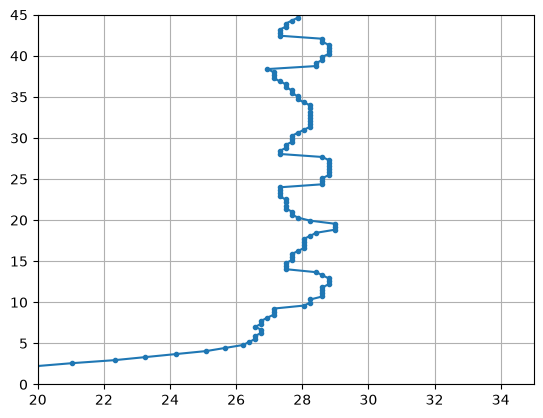

In [12]:
plt.plot(r, z, '.-')
plt.xlim(20, 35)
plt.ylim(0, 45)
plt.grid(True)
plt.show()

In [20]:
from scipy.interpolate import UnivariateSpline
keep=z>7
z,r=z[keep],r[keep]
o=np.argsort(z)
z,r=z[o],r[o]
spl=UnivariateSpline(z,r,k=3,s=len(z)*0.15**2)
zz=np.linspace(z.min(),z.max(),1000)
rr=np.clip(spl(zz),0,None)
V=np.trapezoid(rr**2,zz)*np.pi/1000.0
print(V)


495.1434823261142


In [26]:
import open3d as o3d
n_theta=120
th=np.linspace(0,2*np.pi,n_theta,endpoint=False)
ct,st=np.cos(th),np.sin(th)
nz=len(zz)
V=np.empty((nz*n_theta+2,3))
for i in range (nz):
    V[i*n_theta:(i+1)*n_theta,0]=rr[i]*ct
    V[i*n_theta:(i+1)*n_theta,1]=rr[i]*st
    V[i*n_theta:(i+1)*n_theta,2]=zz[i]
idx=lambda i,j:i*n_theta+j%n_theta
F=[]
for i in range(nz-1):
    for j in range(n_theta):
        a,b=idx(i,j),idx(i,j+1)
        c,d=idx(i+1,j+1),idx(i+1,j)
        F+=[[a,b,c],[a,c,d]]
ib=nz*n_theta;V[ib]=[0,0,zz[0]]
for j in range(n_theta):
    F.append([ib,idx(0,j+1),idx(0,j)])
it=ib+1;V[it]=[0,0,zz[-1]]
for j in range(n_theta):
    F.append([it,idx(nz-1,j),idx(nz-1,j+1)])
        
        

In [27]:
mesh = o3d.geometry.TriangleMesh(
    o3d.utility.Vector3dVector(V),
    o3d.utility.Vector3iVector(F))
mesh.compute_vertex_normals()

print("水密:", mesh.is_watertight())
print("网格体积:", mesh.get_volume()/1000)
o3d.io.write_triangle_mesh("cup.obj", mesh)

水密: True
网格体积: 494.88643962254486
[Open3D WARNING] Write OBJ can not include triangle normals.


True